# LSTM Practice Implementation

## Configuring MPS

In [2]:
import torch
import torch.nn as nn

#Set the device automatically: Cuda/Mps
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print(f"Using device: {device}")

Using device: mps


## Viewing the CSV

In [3]:
import pandas as pd

df = pd.read_csv("rdb5_data.csv")

df.head(5)

/var/folders/cj/rxl_zw1j7jz82tt4ktrl_w040000gn/T/ipykernel_53911/3545351190.py:3: DtypeWarning: Columns (0: TRAILER_ID) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("rdb5_data.csv")


,ID,TIMESTAMP,OBJID,UTM_X,UTM_Y,UTM_ANGLE,V,ACC,ACC_LAT,ACC_TAN,CLASS,WIDTH,LENGTH,TRAILER_ID
0,1,0.000000,57687,617396.68,5806787.75,1.526085,7.64,0.7646,-0.7640,0.0323,Car,2.0149,4.4885,NaN
1,2,0.033367,57687,617396.69,5806788.00,1.529885,7.64,0.8675,-0.8671,0.0253,Car,2.0149,4.4885,NaN
2,3,0.066733,57687,617396.69,5806788.26,1.533185,7.64,0.9703,-0.9702,0.0158,Car,2.0149,4.4885,NaN
3,4,0.100100,57687,617396.70,5806788.51,1.536085,7.64,1.0743,-1.0743,-0.0071,Car,2.0149,4.4885,NaN
4,5,0.133467,57687,617396.70,5806788.77,1.538885,7.64,1.1802,-1.1794,-0.0434,Car,2.0149,4.4885,NaN


In [4]:
#considering vehicle classes
print(df['CLASS'].value_counts())

CLASS
Car               1262670
Pedestrian         185361
Medium Vehicle     148991
Bicycle             79396
Heavy Vehicle       38987
Trailer             33846
Bus                 14498
Motorcycle           3274
Name: count, dtype: int64


## Filtering the Data

In [5]:
#keeping only vehicle classes
vehicle_classes = [
    "Car",
    "Medium Vehicle",
    "Trailer",
    "Bus",
    "Heavy Vehicle",
    "Motorcycle"
]

df = df[df["CLASS"].isin(vehicle_classes)]

In [6]:
#verification
print(df["CLASS"].value_counts())

CLASS
Car               1262670
Medium Vehicle     148991
Heavy Vehicle       38987
Trailer             33846
Bus                 14498
Motorcycle           3274
Name: count, dtype: int64


In [7]:
#removal of less the 150 object observations
trajectory_lengths = df.groupby("OBJID").size()
valid_objids = trajectory_lengths[trajectory_lengths >= 150].index
df = df[df["OBJID"].isin(valid_objids)]

## Creating Sliding Windows

In [8]:
# #inspecting total data points amount
# positions = df[["UTM_X", "UTM_Y"]].values
# print(positions.shape)

In [9]:
# #defining input and target (first 60, next 90)
# input_positions = positions[:60]
# target_positions = positions[60:150]

# #verification
# print(input_positions.shape, target_positions.shape)

In [10]:
# #making coordinates relative to the starting point
# origin = input_positions[0]
# input_relative = input_positions - origin
# target_relative = target_positions - origin

# #verification
# print(input_relative[0])
# print(target_relative[0])

In [175]:
import numpy as np

def make_windows(positions, input_length=60, target_length=90, stride=10):
    inputs = []
    targets = []

    total_length = input_length + target_length

    for start in range(0, len(positions) - total_length + 1, stride):
        #set current window
        window = positions[start: (start + total_length)]

        #split window into input and target (60/90)
        #input is more than just position (other features so far: angle, output remains just position 
        input_data = window[:input_length]
        target_positions = window[input_length:]

        origin = input_data[0, :2]

        #just subtract from x and y coords, don't confuse with angle
        input_relative = input_data[:, :2] - origin
        target_relative = target_positions[:, :2] - origin

        #adding angle as a feature
        initial_angle = input_data[0, 2]
        relative_angle = input_data[:, 2] - initial_angle

        #np.sin and cos expect angle in radians
        relative_angle = np.deg2rad(relative_angle)

        #sin/cos encoding
        angle_sin = np.sin(relative_angle)
        angle_cos = np.cos(relative_angle)

        #combine x, y, sin(angle), cos(angle) together as input features
        input_features = np.column_stack((
            input_relative,
            angle_sin,
            angle_cos
        ))

        inputs.append(input_features)
        targets.append(target_relative)

    return inputs, targets

In [12]:
# inputs, targets = make_windows(positions)

# print(len(inputs))
# print(inputs[0].shape)
# print(targets[0].shape)

In [13]:
#define train, validate, test split (70/15/15) by objectID so same vehicle isn't used in train and test (cheating)
import numpy as np

#create array of only unique vehicles, to ensure all observations from the same vehicle remain in the same train, val or test set 
vehicle_ids = df["OBJID"].unique()

np.random.seed(1)

np.random.shuffle(vehicle_ids)

n = len(vehicle_ids)

#splitting the vehicle ids between sets
train_ids = vehicle_ids[:int(0.7 * n)]
val_ids = vehicle_ids[int(0.7 * n):int(0.85 * n)]
test_ids = vehicle_ids[int(0.85 * n):]

#verification
print(len(train_ids))
print(len(val_ids))
print(len(test_ids))

2808
602
602


## Making Train, Val and Test Sets

In [14]:
def create_dataset(df, vehicle_ids):
    inputs = []
    targets = []
    metadata = []

    for objid in vehicle_ids:
        #get all obserations of just one vehicle from the df
        vehicle = df[df["OBJID"] == objid]

        #get the just the features of importance (x and y pos) and now angle
        positions = vehicle[["UTM_X", "UTM_Y", "UTM_ANGLE"]].values

        #get the first 60 observations of each window and following 90.
        vehicle_inputs, vehicle_targets = make_windows(positions)

        inputs.extend(vehicle_inputs)
        targets.extend(vehicle_targets)

        #tracking where each window came from
        for start in range(0, len(positions) - 150 + 1, 10):
            metadata.append((objid, start))

    return inputs, targets, metadata

In [15]:
# defining each set through the create dataset function using the df and the specific ids attatched to each set
#now includes metadata for tracking real-world starting location 
train_inputs, train_targets, train_metadata = create_dataset(df, train_ids)
val_inputs, val_targets, val_metadata = create_dataset(df, val_ids)
test_inputs, test_targets, test_metadata = create_dataset(df, test_ids)

#validation
print("Train:", len(train_inputs))
print("Validation:", len(val_inputs))
print("Test:", len(test_inputs))

Train: 64452
Validation: 13912
Test: 13515


## Converting Data to PyTorch Tensors

In [16]:
#converting to tensors for pytorch use
train_inputs = torch.tensor(train_inputs, dtype=torch.float32)
train_targets = torch.tensor(train_targets, dtype=torch.float32)

val_inputs = torch.tensor(val_inputs, dtype=torch.float32)
val_targets = torch.tensor(val_targets, dtype=torch.float32)

test_inputs = torch.tensor(test_inputs, dtype=torch.float32)
test_targets = torch.tensor(test_targets, dtype=torch.float32)

/var/folders/cj/rxl_zw1j7jz82tt4ktrl_w040000gn/T/ipykernel_53911/2732108963.py:2: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:255.)
  train_inputs = torch.tensor(train_inputs, dtype=torch.float32)


In [17]:
# #verification
# print(train_inputs.shape)
# print(train_targets.shape)
# print(val_inputs.shape)
# print(val_targets.shape)
# print(test_inputs.shape)
# print(test_targets.shape)

## Making PyTorch Dataset

In [18]:
#the dataset stores data examples and their corresponding labels
#and gives us one example at a time
from torch.utils.data import Dataset

class TrajectoryDataset(Dataset):
    def __init__(self, inputs, targets):
        self.inputs = inputs
        self.targets = targets

    def __len__(self):
        return len(self.inputs)

    def __getitem__(self, index):
        return self.inputs[index], self.targets[index]

In [19]:
train_dataset = TrajectoryDataset(train_inputs, train_targets)
val_dataset = TrajectoryDataset(val_inputs, val_targets)
test_dataset = TrajectoryDataset(test_inputs, test_targets)

In [20]:
# x, y = train_dataset[0]

# print(x.shape)
# print(y.shape)

## Making Pytorch Dataloader

In [21]:
# DataLoader groups examples into batches
from torch.utils.data import DataLoader

# Only shuffle the training data so the model get examples
# in a different order each epoch
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

## Defining LSTM Architecture

In [22]:
class TrajectoryLSTM(nn.Module):
    def __init__(self):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=4,
            hidden_size=128, #sensible moderate hyperparameter, however, may change during validation
            num_layers=2,
            batch_first=True
        )

        self.linear = nn.Linear(128, 180)

        #this direct-prediction architecture is a simplified starting point, sequence to sequence may be better later
        #direct prediction: predict all 90 future locations
        #sequence-to-sequence: predict future locations one at a time
        
    def forward(self, x):
        #pass the input through the LSTM
        output, (hidden, cell) = self.lstm(x)
    
        # #remove the unnecessary layer dimension ONLY works when layer dimension is 1
        # hidden = hidden.squeeze(0)

        #get just last element instead of removing first layer dimenion
        hidden = hidden[-1]
    
        #produce 180 numbers
        output = self.linear(hidden)
    
        #turn those 180 numbers into coordinates, -1 in case last batch size isn't the full 32
        output = output.reshape(-1, 90, 2)
    
        return output
        
        #If x = (32, 60, 4), then output = (32, 60, 64), hidden = (1, 32, 64), cell   = (1, 32, 64)
        # output — the hidden state at every one of the 60 input timesteps
        # hidden — the final hidden state
        # cell — the final cell state


## Instantiating Model

In [23]:
model = TrajectoryLSTM()
model = model.to(device)

## Defining Loss Function (MSE)

In [24]:
#returns PyTorch Tensor, because PyTorch needs to track the computational graph so that it can later calc gradients
#computational graph is the trail of how the value came to be input->LSTM->prediction->MSEloss
#loss.item() gives the associated float
loss_fn = nn.MSELoss()

## Optimiser

In [25]:
#utilising PyTorch's Adam Optimiser 
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

## Completing One Full Training Cycle on a Batch

In [26]:
# # reset optimiser gradient
# optimizer.zero_grad()

# # make new prediction using batch
# prediction = model(x_batch)

# #calculate loss
# loss = loss_fn(prediction, y_batch)

# #calculate gradients for optimisation step
# loss.backward()

# #update weights accordingly 
# optimizer.step()

## Full Epoch

In [27]:
# model.train()

# total_loss = 0

# for x_batch, y_batch in train_loader:

#     optimizer.zero_grad()

#     prediction = model(x_batch)

#     loss = loss_fn(prediction, y_batch)

#     loss.backward()

#     optimizer.step()

#     total_loss += loss.item()

# average_loss = total_loss / len(train_loader)

# print("Training loss:", average_loss)

## Multiple Epochs

In [28]:
run_epochs = False

if run_epochs:
    num_epochs = 20
    losses = []
    
    for epoch in range(num_epochs):
    
        model.train()
    
        total_loss = 0
    
        for x_batch, y_batch in train_loader:
    
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)
    
            optimizer.zero_grad()
    
            prediction = model(x_batch)
    
            loss = loss_fn(prediction, y_batch)
    
            loss.backward()
    
            optimizer.step()
    
            total_loss += loss.item()
    
        average_loss = total_loss / len(train_loader)
        
        losses.append(average_loss)
    
        print("Epoch:", epoch + 1, "Training loss:", average_loss)

## Graphing Loss vs Epoch

In [29]:
if run_epochs:
    import matplotlib.pyplot as plt
    plt.plot(range(1, num_epochs + 1), losses)
    
    plt.xlabel("Epoch Number")
    plt.ylabel("Training Loss (MSE)")
    plt.title("Training Loss per Epoch")
    
    plt.show()
else:
    #loading in pretrained model, here if not training new one
    model.load_state_dict(torch.load('h128_n2_e80_f4.pt', weights_only=True))
    

## Model Evaluation

In [30]:
model.eval()

total_loss = 0

#no gradient calculation/ model is not changing
with torch.no_grad():

    for x_batch, y_batch in val_loader:

        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        prediction = model(x_batch)

        loss = loss_fn(prediction, y_batch)

        total_loss += loss.item()

average_val_loss = total_loss / len(val_loader)

print("Validation loss:", average_val_loss)

Validation loss: 0.6579262837253768


## Inference of Unseen Trajectory

In [31]:
print(len(test_inputs))
x_test = test_inputs[500]
y_test = test_targets[500]

#unsqueeze to allow a single example batch
x_test = x_test.unsqueeze(0).to(device)

model.eval()

with torch.no_grad():
    prediction = model(x_test)

#remove batch dimension
prediction = prediction.squeeze(0)

13515


In [32]:
#converting tensors to np arrays for plotting
observed = x_test.squeeze(0).cpu().numpy()
actual = y_test.numpy()
predicted = prediction.cpu().numpy()

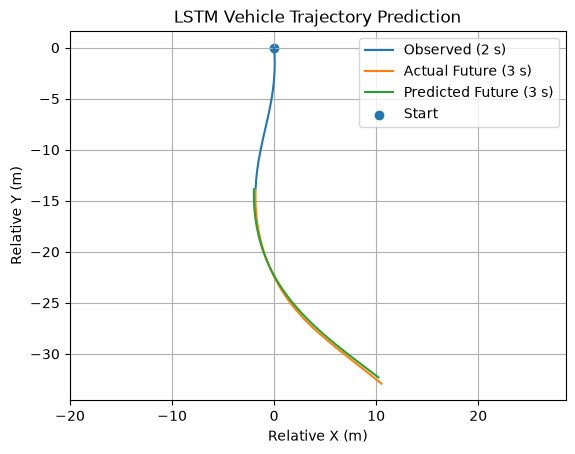

In [33]:
import matplotlib.pyplot as plt

plt.plot(observed[:, 0], observed[:, 1], label="Observed (2 s)")
plt.plot(actual[:, 0], actual[:, 1], label="Actual Future (3 s)")
plt.plot(predicted[:, 0], predicted[:, 1], label="Predicted Future (3 s)")

plt.scatter(0, 0, label="Start")

plt.xlabel("Relative X (m)")
plt.ylabel("Relative Y (m)")
plt.title("LSTM Vehicle Trajectory Prediction")

plt.axis("equal")
plt.legend()
plt.grid()

plt.show()

In [34]:
mse = loss_fn(prediction, y_test.to(device))

print("MSE:", mse.item())

MSE: 0.04590439423918724


In [35]:
objid, start = test_metadata[500]

print("Vehicle:", objid)
print("Starting frame:", start)

Vehicle: 61651
Starting frame: 100


In [36]:
vehicle = df[df["OBJID"] == objid]

positions = vehicle[["UTM_X", "UTM_Y"]].values

origin = positions[start]

observed_utm = positions[start:start + 60]

actual_utm = positions[start + 60:start + 150]

print(observed_utm[0])
print(actual_utm[-1])

print(actual_utm[-1] - observed_utm[0])

[ 617371.93 5806809.69]
[ 617382.44 5806776.77]
[ 10.51 -32.92]


## Saving Pretrained Models

In [37]:
#Path is h<hidden layer size>_n<num_ber of layers>_e<number of epochs>_f<number_of_input_features>.pt

#model_name = "h128_n2_e80_f4.pt"
#torch.save(model.state_dict(), model_name) 

## Implementing Cyclist Class with Trajectory

In [38]:
class Cyclist:
    #parameters will be randomised during inference
    def __init__(self, position: tuple, speed: float, direction: float):
        self.position = position #tuple of x,y location 
        self.speed = speed/3.6 #paramater of speed in km/h converted to m/s
        self.direction = np.deg2rad(direction) #parameter of direction in degrees converted to radians
        self.trajectory = self.create_trajectory()

    def create_trajectory(self):
        trajectory = []
        
        for i in range (0, 150):
            next_position = (self.position[0] + self.speed * np.cos(self.direction) * i/30, self.position[1] + self.speed * np.sin(self.direction) * i/30) 
            trajectory.append(next_position) 

        return trajectory
    
    def get_trajectory(self):
        return np.array(self.trajectory)

    def get_direction(self):
        return np.rad2deg(self.direction)

    def get_speed(self):
        return self.speed

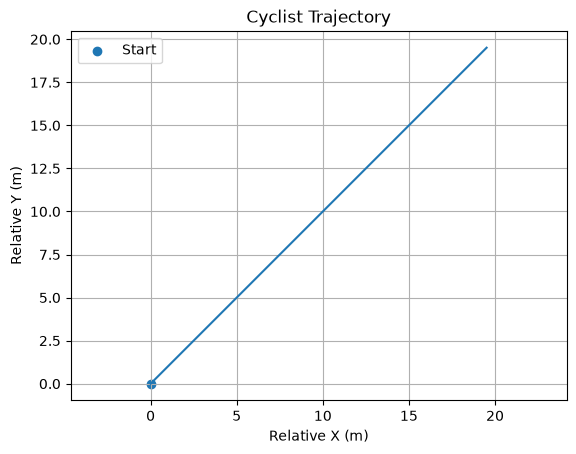

In [39]:
import matplotlib.pyplot as plt

#Testing cyclist class implementation
cyclist = Cyclist(position=(0, 0), speed=20, direction=45)

#convert trajectory tuple list to numpy array
trajectory = cyclist.get_trajectory()

#extract coords
x = trajectory[:,0]
y = trajectory[:,1]

plt.close('all')

plt.plot(x, y)

plt.scatter(0, 0, label="Start")

plt.xlabel("Relative X (m)")
plt.ylabel("Relative Y (m)")
plt.title("Cyclist Trajectory")

plt.axis("equal")
plt.legend()
plt.grid()

plt.show()

## Time to Collision

In [40]:
#loading in pretrained model
model.load_state_dict(torch.load('h128_n2_e80_f4.pt', weights_only=True))

<All keys matched successfully>

In [41]:
vehicle_observed = test_inputs[500]
vehicle_real = test_targets[500]

#unsqueeze to allow a single example batch
vehicle_observed = vehicle_observed.unsqueeze(0).to(device)

model.eval()

with torch.no_grad():
    prediction = model(vehicle_observed)

#remove batch dimension
prediction = prediction.squeeze(0)

#converting tensors to np arrays for plotting
observed = vehicle_observed.squeeze(0).cpu().numpy()
actual = vehicle_real.numpy()
predicted = prediction.cpu().numpy()

In [155]:
#importing math for euclidean distance calculation
import math

#initialise cyclist
cyclist = Cyclist(position=(4, -50), speed=20, direction=90)

tolerance = 1
crash_flagged = False
crash_frame_number = None

for i in range(len(predicted)):
    coordinates_distance = predicted[i] - cyclist.get_trajectory()[i+60]
    euclidean_distance = math.sqrt(coordinates_distance[0]**2 + coordinates_distance[1]**2)
    
    if euclidean_distance <= tolerance:
        print(f"Crash Risk Anticipated in {i/30} seconds")
        crash_flagged = True
        crash_frame_number = i
        break

if not crash_flagged:
    print("No Crash Anticipated")

Crash Risk Anticipated in 1.9666666666666666 seconds


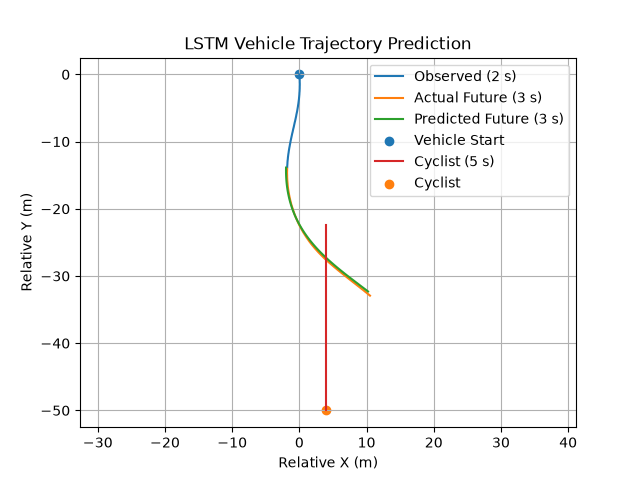

In [158]:
plt.close('all')

#Vehicle trajectory segments
plt.plot(observed[:, 0], observed[:, 1], label="Observed (2 s)")
plt.plot(actual[:, 0], actual[:, 1], label="Actual Future (3 s)")
plt.plot(predicted[:, 0], predicted[:, 1], label="Predicted Future (3 s)")

plt.scatter(0, 0, label="Vehicle Start")

#Example Cyclist Trajectory
plt.plot(cyclist.get_trajectory()[:,0], cyclist.get_trajectory()[:,1], label="Cyclist (5 s)")

plt.scatter(4, -50, label="Cyclist")


plt.xlabel("Relative X (m)")
plt.ylabel("Relative Y (m)")
plt.title("LSTM Vehicle Trajectory Prediction")

plt.axis("equal")
plt.legend()
plt.grid()

plt.show()

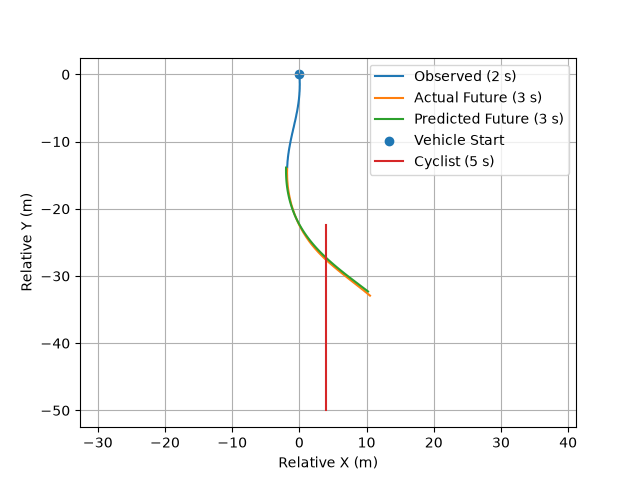

In [159]:
#run at start so reference to past animations is not lost
if 'animation' in globals():
    animation.event_source.stop()

plt.close("all")

#needed for animations in jupyter notebook
%matplotlib widget

#animation library
from matplotlib.animation import FuncAnimation

#create new figure for animation
fig = plt.figure()

#vehicle trajectory segments
plt.plot(observed[:, 0], observed[:, 1], label="Observed (2 s)")
plt.plot(actual[:, 0], actual[:, 1], label="Actual Future (3 s)")
plt.plot(predicted[:, 0], predicted[:, 1], label="Predicted Future (3 s)")

plt.scatter(0, 0, label="Vehicle Start")

#cyclist trajectory
trajectory = cyclist.get_trajectory()
plt.plot(trajectory[:, 0], trajectory[:, 1], label="Cyclist (5 s)")

#animation of points
point_c, = plt.plot([], [], 'o')
point_v, = plt.plot([], [], 'o')

#labelling graph
plt.xlabel("Relative X (m)")
plt.ylabel("Relative Y (m)")
plt.legend()
plt.grid()
plt.axis('equal')

#combining observed vehicle path and predicted future trajectories
observed_and_predicted = np.vstack((observed[:,:2], predicted))

#updating location of point_c and v for animation
def update(i):
    point_c.set_data([trajectory[i, 0]], [trajectory[i, 1]])
    point_v.set_data([observed_and_predicted[i, 0]], [observed_and_predicted[i, 1]])

    return point_c, point_v

#running animation
animation = FuncAnimation(
    fig,
    update,
    frames=len(trajectory),
    interval=20
)

plt.show()

## Determining Relative Collision Speed

In [160]:
#Defining Relative Collision Function
#RCS measures the magnitude of the difference between two objects’ 
#velocity vectors, accounting for both their speeds and directions of 
#travel to estimate their relative speed at the point of collision
def relativeCollisionSpeed(vehicle_speed: float, cyclist_speed: float, vehicle_angle: float, cyclist_angle: float):
    angle_difference = cyclist_angle - vehicle_angle
    angle_radians = math.radians(angle_difference)

    relative_collision_speed = math.sqrt(
        vehicle_speed**2 +
        cyclist_speed**2 -
        2 * vehicle_speed * cyclist_speed * math.cos(angle_radians)
    )

    return relative_collision_speed

In [161]:
#Vehicle Angle
#getting vehicle position during crash and just before to calculate angle
veh_precrash_coord = observed_and_predicted[crash_frame_number+59]
veh_crash_coord = observed_and_predicted[crash_frame_number+60]

#calculating vehicle bearing
veh_crash_angle = np.rad2deg(math.atan2(veh_crash_coord[0] - veh_precrash_coord[0], veh_crash_coord[1] - veh_precrash_coord[1]))

#changing angle to measure from the horizontal
veh_crash_angle -= 90

#measuing anticlockwise
veh_crash_angle *= -1
print(f"Vehicle angle at point of collision is: {veh_crash_angle} (relative to the horizontal)")

#Vehicle Speed (m/s)
vehicle_distance = veh_crash_coord - veh_precrash_coord
veh_crash_speed = math.sqrt(vehicle_distance[0]**2 + vehicle_distance[1]**2) * 30 #multiply by 30 as vehicle is sampled at 30Hz 

#Cyclist Angle
cyc_crash_angle = cyclist.get_direction()
print(f"Cyclist angle at point of collision is: {cyc_crash_angle} (relative to the horizontal)")

#Cyclist Speed (m/s)
cyc_crash_speed = cyclist.get_speed()

RCS = relativeCollisionSpeed(veh_crash_speed, cyc_crash_speed, veh_crash_angle, cyc_crash_angle)

print(f"Relative Collision Speed {RCS}")    

Vehicle angle at point of collision is: -44.20388919326288 (relative to the horizontal)
Cyclist angle at point of collision is: 90.0 (relative to the horizontal)
Relative Collision Speed 12.495710548254781


## Determining Severity and Warning Cyclist

In [163]:
#Crash is severe if it is at high speed and there is insufficient time to react

TTC = crash_frame_number/30 

#time to percieve a dangerous event and react 85th percentile this 1.3 seconds (U.S. Department of Transportation, Federal Highway Administration, 2004, Table 14) + 1 second for braking
perception_reaction_time = 2.3

#dangerous speed is the speed at which collisions result in > 10% chance of fatality. This is 30kmh (Harding Mazzotti, 2026)
dangerous_speed = 30/3.6

if TTC <= perception_reaction_time:
    print("Not enough time for standard perception-reaction.")
    if RCS >= dangerous_speed: 
        print("Collision anticipated at or above dangerous speed.")
        print(f"WARNING HIGH RISK COLLISION ANTICIPATED")

Not enough time for standard perception-reaction.
Collision anticipated at or above dangerous speed.
WARNING HIGH RISK COLLISION ANTICIPATED


## Evaluating False Positives

In [209]:
#run all test inputs through the model 
#then run all through crash detected
#if collisions detected in prediction and not target or vice versa increament false pos/neg counter
import random
evaluate_accuracy = True

if evaluate_accuracy:
    #running test data through model on eval, no gradient mode
    model.eval()

    test_predictions = []
    test_actual_trajectories = []

    with torch.no_grad():

        for x_batch, y_batch in test_loader:
    
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)
    
            prediction = model(x_batch)
    
            test_predictions.extend(prediction.cpu().numpy())
            test_actual_trajectories.extend(y_batch.cpu().numpy())

    #generate random cyclist for each trajectory and check if collision occurs between cyclist and predicted trajectory
    #and compare if collision occurs between cycist and actual trajectory 
    random.seed(1)

    #keep count of false positive and negatives
    false_positives = 0
    false_negatives = 0

    #keeping number of real and fake collsions from more data
    num_collisions = 0
    correctly_predicted_collisions = 0
    
    for traj in range(len(test_predictions)):
        #instantiate a new cyclist with random attributes
        random_position = (random.uniform(-20, 20), random.uniform(-20, 20))
        random_speed = random.uniform(5, 30)
        random_direction = random.uniform(0, 360)
        cyclist = Cyclist(random_position, random_speed, random_direction)

        #check if collsions occurs based on prediction and based on reality
        crash_predicted = isCrashDetected(cyclist, test_predictions[traj])
        crash_occurs = isCrashDetected(cyclist, test_actual_trajectories[traj])

        #increment appropriate counters
        if(crash_predicted and  not crash_occurs):
            false_positives += 1
        
        elif(not crash_predicted and crash_occurs):
            false_negatives += 1       

        #increment collision counters
        if crash_occurs:  
            num_collisions += 1
            if crash_predicted:
                correctly_predicted_collisions += 1

In [188]:
#importing math for euclidean distance calculation
import math

def isCrashDetected(cyclist: Cyclist, predicted):
    tolerance = 1
    
    for i in range(len(predicted)):
        coordinates_distance = predicted[i] - cyclist.get_trajectory()[i+60]
        euclidean_distance = math.sqrt(coordinates_distance[0]**2 + coordinates_distance[1]**2)
        
        if euclidean_distance <= tolerance:
            return True
    
    if not crash_flagged:
        return False

In [210]:
wrong_output = false_positives + false_negatives

print(f"There were {false_positives} false positives and {false_negatives} false negatives")
print()
print(
    f"Out of {len(test_predictions)} the output was correct "
    f"{(len(test_predictions) - wrong_output) / len(test_predictions) * 100}% of the time"
)
print()
print(f"There were {num_collisions} total collisions and {num_detected_collisions} collisions detected")

There were 17 false positives and 23 false negatives

Out of 13515 the output was correct 99.7040325564188% of the time

There were 129 total collisions and 123 collisions detected
